In [50]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import textwrap

In [52]:
CHECAGENS = r"C:\Users\danie\projects\fact_check\dados_checagem\checagens.csv"
GRAFICO_POR_PORTAL = r"C:\Users\danie\projects\fact_check\figures\checagens_barras.png"
GRAFICO_EMPILHADO = r"C:\Users\danie\projects\fact_check\figures\checagens_barras_empilhadas.png"

In [26]:
df_checagens = pd.read_csv(CHECAGENS, sep=";")

In [45]:
df_checagens = df_checagens[
    df_checagens["portal_publicador"] != "Brasil Paralelo"
].copy()

In [49]:
df_checagens.columns

Index(['checagem_id', 'alegacao_id', 'candidato', 'agencia',
       'portal_publicador', 'grupo_origem', 'tema_curto', 'veredito_original',
       'tipo_veredito', 'categoria', 'fonte_id', 'fonte_url', 'localizador',
       'data_debate', 'data_acesso', 'observacao'],
      dtype='object')

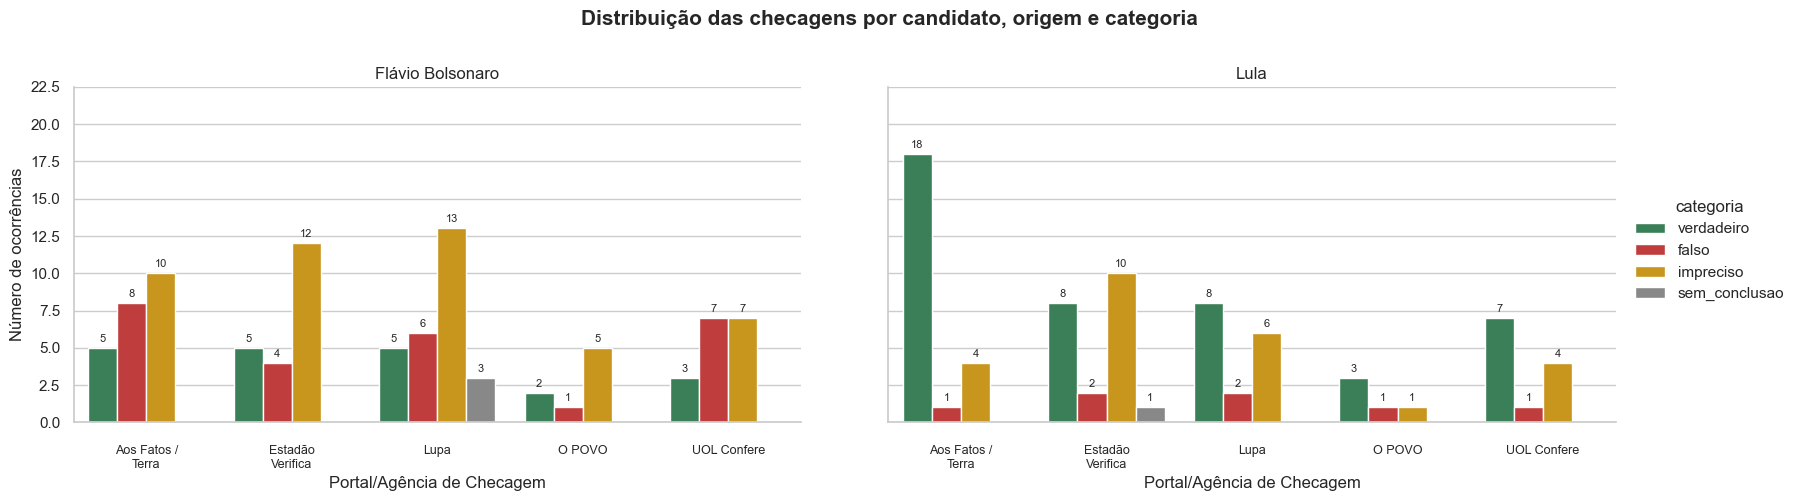

In [57]:
# ============================================================
# 2. DEFINIR CATEGORIAS E CORES
# ============================================================

categorias = [
    "verdadeiro",
    "falso",
    "impreciso",
    "sem_conclusao"
]

paleta = {
    "verdadeiro": "#2E8B57",
    "falso": "#D62728",
    "impreciso": "#E5A000",
    "sem_conclusao": "#888888"
}

# ============================================================
# 3. CONTAR OCORRÊNCIAS
# ============================================================

contagens = (
    df_checagens.groupby(
        ["candidato", "grupo_origem", "categoria"]
    )
    .size()
    .reset_index(name="quantidade")
)

ordem_grupos = sorted(df_checagens["grupo_origem"].unique())

# ============================================================
# 4. CONFIGURAÇÃO VISUAL
# ============================================================

sns.set_theme(
    style="whitegrid",
    font_scale=1.0
)

# ============================================================
# 5. CRIAR GRÁFICO DE BARRAS AGRUPADAS
# ============================================================

g = sns.catplot(
    data=contagens,
    x="grupo_origem",
    y="quantidade",
    hue="categoria",
    col="candidato",
    kind="bar",
    order=ordem_grupos,
    hue_order=categorias,
    palette=paleta,
    height=5.5,
    aspect=1.5,
    sharey=True,
    errorbar=None,
    legend=True
)

# ============================================================
# 6. AJUSTAR TÍTULOS E EIXOS
# ============================================================

g.set_titles("{col_name}")

g.set_axis_labels(
    "Portal/Agência de Checagem",
    "Número de ocorrências"
)

# ============================================================
# 7. CENTRALIZAR LABELS DOS GRUPOS
# ============================================================

for ax in g.axes.flat:

    # Recuperar posições e nomes dos grupos
    posicoes = ax.get_xticks()

    labels = [
        textwrap.fill(
            label.get_text(),
            width=14,
            break_long_words=False,
            break_on_hyphens=False
        )
        for label in ax.get_xticklabels()
    ]

    # Centralizar cada label abaixo do seu grupo de barras
    ax.set_xticks(
        posicoes,
        labels=labels,
        rotation=0,
        ha="center"
    )

    ax.tick_params(
        axis="x",
        labelsize=9,
        pad=10
    )

    # ========================================================
    # 8. INSERIR VALORES ACIMA DAS BARRAS
    # ========================================================

    for container in ax.containers:

        valores = [
            str(int(bar.get_height()))
            if bar.get_height() > 0 else ""
            for bar in container
        ]

        ax.bar_label(
            container,
            labels=valores,
            padding=3,
            fontsize=8
        )

    # Espaço adicional acima das barras
    ax.set_ylim(
        0,
        contagens["quantidade"].max() * 1.25
    )

# ============================================================
# 9. TÍTULO PRINCIPAL
# ============================================================

g.fig.suptitle(
    "Distribuição das checagens por candidato, origem e categoria",
    fontsize=15,
    fontweight="bold"
)

# Ajustar margens e espaçamento entre painéis
g.fig.subplots_adjust(
    top=0.84,
    bottom=0.23,
    wspace=0.12
)

# ============================================================
# 10. SALVAR E EXIBIR
# ============================================================

g.fig.savefig(
    GRAFICO_POR_PORTAL,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


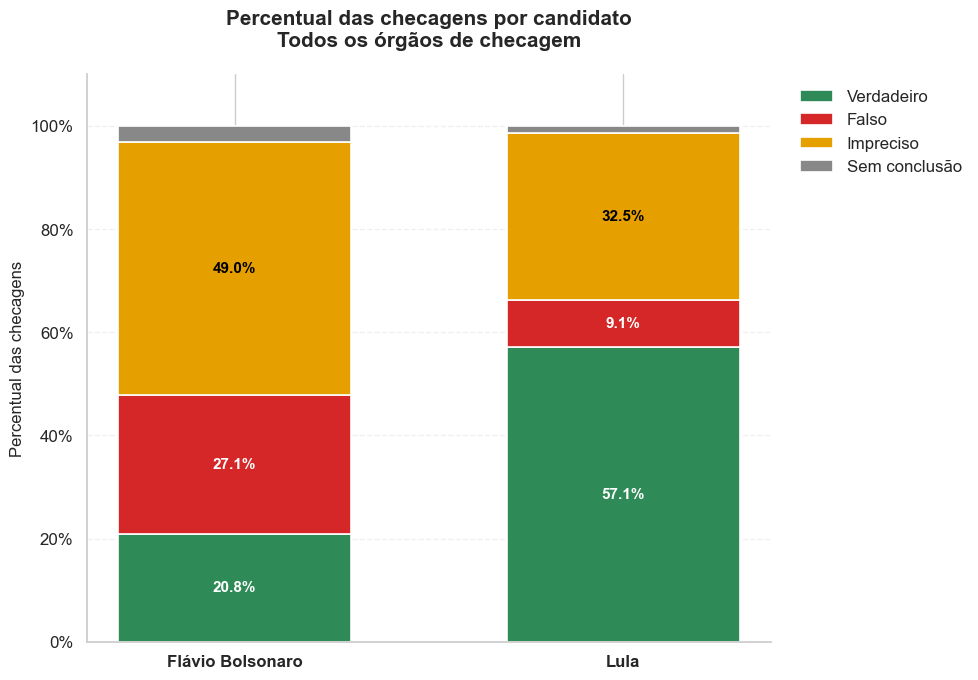

categoria,verdadeiro,falso,impreciso,sem_conclusao
candidato,,,,
Flávio Bolsonaro,20.83,27.08,48.96,3.12
Lula,57.14,9.09,32.47,1.30


In [55]:
# ============================================================
# 1. PREPARAR OS DADOS
# ============================================================

df = df_checagens.copy()

df_checagens["categoria"] = (
    df_checagens["categoria"].astype(str).str.strip().str.lower()
)

categorias = [
    "verdadeiro",
    "falso",
    "impreciso",
    "sem_conclusao"
]

paleta = {
    "verdadeiro": "#2E8B57",
    "falso": "#D62728",
    "impreciso": "#E5A000",
    "sem_conclusao": "#888888"
}

nomes = {
    "verdadeiro": "Verdadeiro",
    "falso": "Falso",
    "impreciso": "Impreciso",
    "sem_conclusao": "Sem conclusão"
}

# ============================================================
# 2. AGREGAR TODOS OS GRUPOS DE ORIGEM
# ============================================================

# Cada registro corresponde a uma checagem.
# Os grupos de origem são somados automaticamente.

contagens = pd.crosstab(
    df_checagens["candidato"],
    df_checagens["categoria"]
).reindex(columns=categorias, fill_value=0)

# Total de checagens por candidato
totais = contagens.sum(axis=1)

# Remover candidatos sem registros
contagens = contagens.loc[totais > 0]
totais = totais.loc[contagens.index]

# Converter contagens em percentuais
percentuais = (
    contagens.div(totais, axis=0) * 100
)

# ============================================================
# 3. CONFIGURAR O GRÁFICO
# ============================================================

sns.set_theme(
    style="whitegrid",
    font_scale=1.1
)

fig, ax = plt.subplots(figsize=(10, 7))

x = np.arange(len(percentuais))
largura = 0.6

# Posição inicial dos segmentos
base = np.zeros(len(percentuais))

# ============================================================
# 4. CRIAR BARRAS EMPILHADAS
# ============================================================

for categoria in categorias:

    valores = percentuais[categoria].to_numpy()

    ax.bar(
        x,
        valores,
        width=largura,
        bottom=base,
        color=paleta[categoria],
        label=nomes[categoria],
        edgecolor="white",
        linewidth=1.2
    )

    # Inserir percentuais dentro dos segmentos
    for i, valor in enumerate(valores):

        # Evitar sobreposição em segmentos pequenos
        if valor >= 5:

            cor_texto = (
                "black"
                if categoria in ["impreciso", "sem_conclusao"]
                else "white"
            )

            ax.text(
                x[i],
                base[i] + valor / 2,
                f"{valor:.1f}%",
                ha="center",
                va="center",
                fontsize=11,
                fontweight="bold",
                color=cor_texto
            )

    # Atualizar a base do próximo segmento
    base += valores

# ============================================================
# 6. FORMATAR EIXOS E TÍTULOS
# ============================================================

ax.set_xticks(x)
ax.set_xticklabels(
    percentuais.index,
    fontsize=12,
    fontweight="bold"
)

ax.set_ylim(0, 110)

ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_yticklabels(
    ["0%", "20%", "40%", "60%", "80%", "100%"]
)

ax.set_ylabel(
    "Percentual das checagens",
    fontsize=12
)

ax.set_xlabel("")

ax.set_title(
    "Percentual das checagens por candidato\n"
    "Todos os órgãos de checagem",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.legend(
    #title="Categoria",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False
)

sns.despine(ax=ax)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)

# ============================================================
# 7. SALVAR E EXIBIR
# ============================================================

plt.tight_layout()

fig.savefig(
    GRAFICO_EMPILHADO,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 8. EXIBIR TABELA DE PERCENTUAIS
# ============================================================

display(percentuais.round(2))
